# Lab 3 Микитюк Антон Андреевич 2374

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, roc_curve,
                             roc_auc_score, auc, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## 1 Предварительная оценка датасета

Используется датасет Wine из предыдущих лабораторных работ

### 1.1 Загрузка данных

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print(f"Размер датасета: {X.shape[0]} записей, {X.shape[1]} признаков")
print(f"Классы: {wine.target_names}")
print(f"\nЦелевой атрибут: target (сорт вина)")
print(f"Количество классов: {len(np.unique(y))}")
print(f"\nРаспределение классов:")
target_counts = pd.Series(y).value_counts().sort_index()
for cls, count in target_counts.items():
    print(f"  Класс {cls} ({wine.target_names[cls]}): {count} образцов ({count/len(y)*100:.1f}%)")

Размер датасета: 178 записей, 13 признаков
Классы: ['class_0' 'class_1' 'class_2']

Целевой атрибут: target (сорт вина)
Количество классов: 3

Распределение классов:
  Класс 0 (class_0): 59 образцов (33.1%)
  Класс 1 (class_1): 71 образцов (39.9%)
  Класс 2 (class_2): 48 образцов (27.0%)


### 1.2 Сбалансированность классов

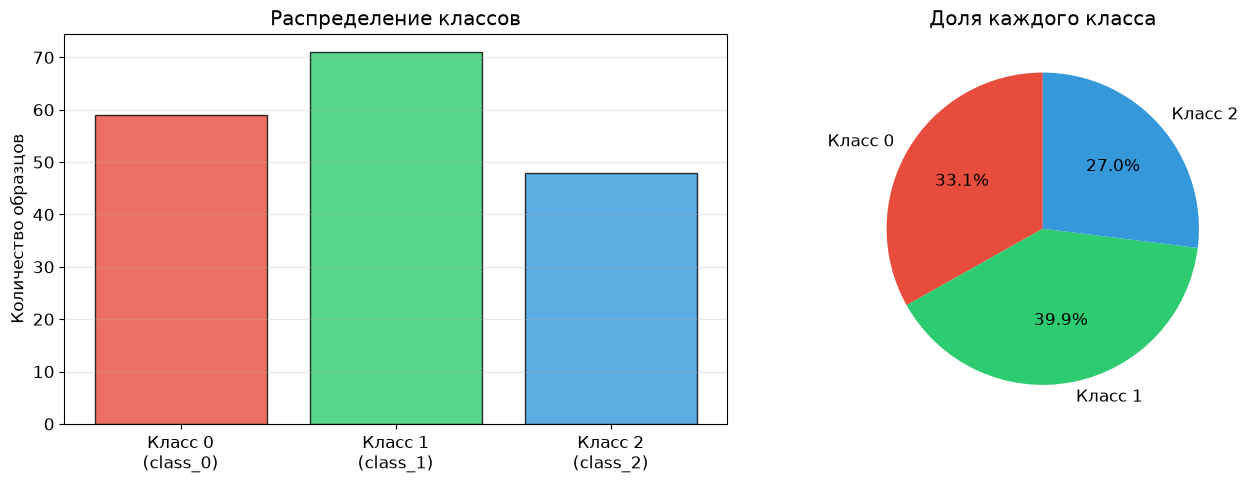


Соотношение макс/мин классов: 1.48
Классы умеренно сбалансированы (соотношение 1.48 < 1.5)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

target_counts = pd.Series(y).value_counts().sort_index()
colors = ['#e74c3c', '#2ecc71', '#3498db']

axes[0].bar(range(3), target_counts.values, color=colors, edgecolor='black', alpha=0.8)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels([f'Класс {i}\n({wine.target_names[i]})' for i in range(3)])
axes[0].set_ylabel('Количество образцов')
axes[0].set_title('Распределение классов')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].pie(target_counts.values, labels=[f'Класс {i}' for i in range(3)],
            colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Доля каждого класса')

plt.tight_layout()
plt.show()

max_count = target_counts.max()
min_count = target_counts.min()
ratio = max_count / min_count
print(f"\nСоотношение макс/мин классов: {ratio:.2f}")
print(f"Классы умеренно сбалансированы (соотношение {ratio:.2f} < 1.5)")

Целевой класс - атрибут target (3 сорта вина). Классы умеренно сбалансированы (59:71:48), соотношение ≈1.48 - датасет подходит для классификации. При разделении используем stratify

## 2 Подготовка данных

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Обучающая выборка: {X_train.shape[0]} записей ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Тестовая выборка:  {X_test.shape[0]} записей ({X_test.shape[0]/len(X)*100:.0f}%)")
print(f"\nРаспределение классов в обучающей выборке:")
for cls, count in pd.Series(y_train).value_counts().sort_index().items():
    print(f"  Класс {cls}: {count} образцов")
print(f"\nРаспределение классов в тестовой выборке:")
for cls, count in pd.Series(y_test).value_counts().sort_index().items():
    print(f"  Класс {cls}: {count} образцов")

Обучающая выборка: 124 записей (70%)
Тестовая выборка:  54 записей (30%)

Распределение классов в обучающей выборке:
  Класс 0: 41 образцов
  Класс 1: 50 образцов
  Класс 2: 33 образцов

Распределение классов в тестовой выборке:
  Класс 0: 18 образцов
  Класс 1: 21 образцов
  Класс 2: 15 образцов


Данные разделены на обучающую (70%) и тестовую (30%) выборки с сохранением пропорций классов (stratify)

## 3 Дерево решений

### 3.1 Подбор гиперпараметров через GridSearchCV

Настраиваем max_depth и max_features, масштабирование для дерева не нужно

In [5]:
tree = DecisionTreeClassifier(random_state=42)

tree_params = {
    'max_depth': range(1, 11),
    'max_features': range(1, 14)
}

tree_grid = GridSearchCV(tree, tree_params, cv=5, n_jobs=-1, scoring='accuracy')
tree_grid.fit(X_train, y_train)

print(f"Лучшие параметры: {tree_grid.best_params_}")
print(f"Лучший результат кросс-валидации (Accuracy): {tree_grid.best_score_:.4f}")

Лучшие параметры: {'max_depth': 4, 'max_features': 4}
Лучший результат кросс-валидации (Accuracy): 0.9357


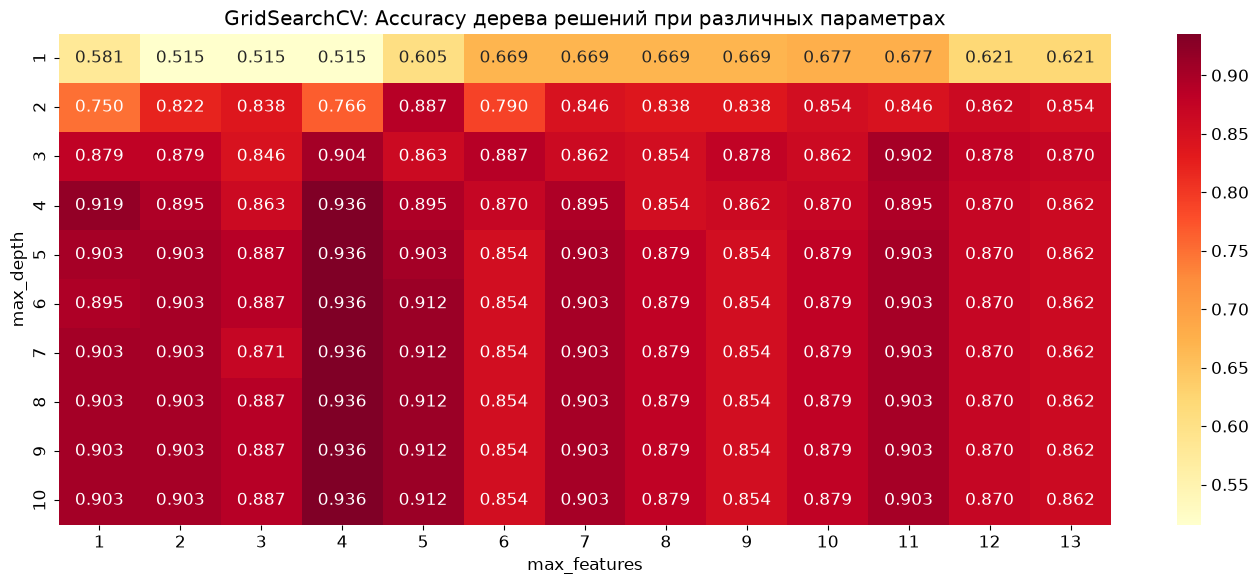

In [6]:
scores = tree_grid.cv_results_['mean_test_score'].reshape(
    len(range(1, 11)), len(range(1, 14))
)

plt.figure(figsize=(14, 6))
sns.heatmap(scores, annot=True, fmt='.3f', cmap='YlOrRd',
            xticklabels=range(1, 14), yticklabels=range(1, 11))
plt.xlabel('max_features')
plt.ylabel('max_depth')
plt.title('GridSearchCV: Accuracy дерева решений при различных параметрах')
plt.tight_layout()
plt.show()

In [7]:
tree_best = tree_grid.best_estimator_
y_pred_tree = tree_best.predict(X_test)
y_proba_tree = tree_best.predict_proba(X_test)

print(f"Accuracy на тестовой выборке: {accuracy_score(y_test, y_pred_tree):.4f}")

Accuracy на тестовой выборке: 0.9259


## 4 Метод ближайших соседей

### 4.1 Подбор гиперпараметров через GridSearchCV

Для kNN масштабирование обязательно, используем Pipeline со StandardScaler. Настраиваем n_neighbors

In [8]:
knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

knn_params = {
    'knn__n_neighbors': range(1, 21)
}

knn_grid = GridSearchCV(knn_pipe, knn_params, cv=5, n_jobs=-1, scoring='accuracy')
knn_grid.fit(X_train, y_train)

print(f"Лучшие параметры: {knn_grid.best_params_}")
print(f"Лучший результат кросс-валидации (Accuracy): {knn_grid.best_score_:.4f}")

Лучшие параметры: {'knn__n_neighbors': 12}
Лучший результат кросс-валидации (Accuracy): 0.9677


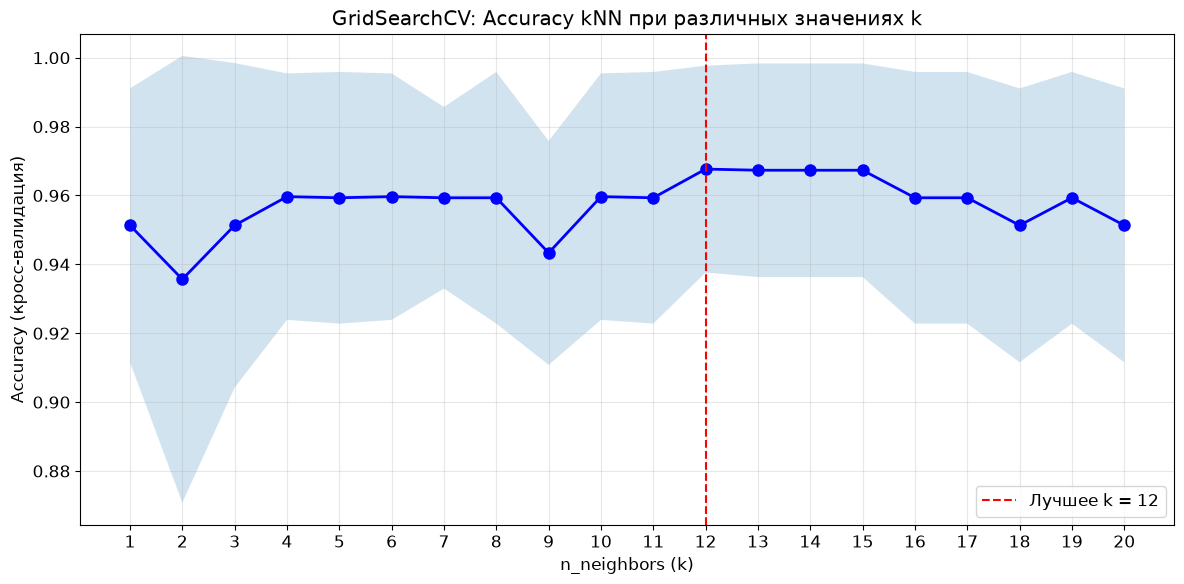

In [9]:
cv_scores = knn_grid.cv_results_['mean_test_score']
cv_std = knn_grid.cv_results_['std_test_score']
k_range = range(1, 21)

plt.figure(figsize=(12, 6))
plt.plot(k_range, cv_scores, 'bo-', linewidth=2, markersize=8)
plt.fill_between(k_range, cv_scores - cv_std, cv_scores + cv_std, alpha=0.2)
plt.xlabel('n_neighbors (k)')
plt.ylabel('Accuracy (кросс-валидация)')
plt.title('GridSearchCV: Accuracy kNN при различных значениях k')
plt.xticks(k_range)
plt.grid(True, alpha=0.3)
best_k = knn_grid.best_params_['knn__n_neighbors']
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Лучшее k = {best_k}')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
knn_best = knn_grid.best_estimator_
y_pred_knn = knn_best.predict(X_test)
y_proba_knn = knn_best.predict_proba(X_test)

print(f"Accuracy на тестовой выборке: {accuracy_score(y_test, y_pred_knn):.4f}")

Accuracy на тестовой выборке: 0.9630


## 5 Метрики качества

### 5.1 Отчёты классификации

In [11]:
print("=" * 60)
print("ДЕРЕВО РЕШЕНИЙ")
print("=" * 60)
print(classification_report(y_test, y_pred_tree, target_names=wine.target_names))

print("\n" + "=" * 60)
print("kNN")
print("=" * 60)
print(classification_report(y_test, y_pred_knn, target_names=wine.target_names))

ДЕРЕВО РЕШЕНИЙ
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.81      0.89        21
     class_2       0.79      1.00      0.88        15

    accuracy                           0.93        54
   macro avg       0.93      0.94      0.93        54
weighted avg       0.94      0.93      0.93        54


kNN
              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.90      0.95        21
     class_2       0.94      1.00      0.97        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



### 5.2 Сравнение метрик

In [12]:
metrics_data = {
    'Метрика': ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1-measure (macro)'],
    'Дерево решений': [
        accuracy_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_tree, average='macro'),
        recall_score(y_test, y_pred_tree, average='macro'),
        f1_score(y_test, y_pred_tree, average='macro')
    ],
    'kNN': [
        accuracy_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_knn, average='macro'),
        recall_score(y_test, y_pred_knn, average='macro'),
        f1_score(y_test, y_pred_knn, average='macro')
    ]
}

metrics_df = pd.DataFrame(metrics_data)
metrics_df[['Дерево решений', 'kNN']] = metrics_df[['Дерево решений', 'kNN']].round(4)
metrics_df

,Метрика,Дерево решений,kNN
0,Accuracy,0.9259,0.9630
1,Precision (macro),0.9298,0.9616
2,Recall (macro),0.9365,0.9683
3,F1-measure (macro),0.9257,0.9636


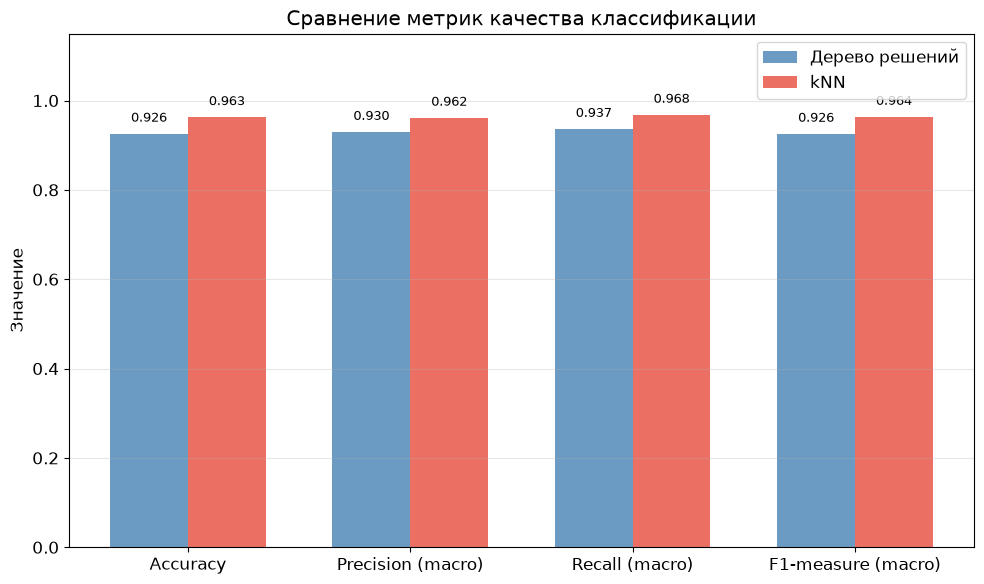

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(metrics_data['Метрика']))
width = 0.35

bars1 = ax.bar(x - width/2, metrics_data['Дерево решений'], width,
               label='Дерево решений', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, metrics_data['kNN'], width,
               label='kNN', color='#e74c3c', alpha=0.8)

ax.set_ylabel('Значение')
ax.set_title('Сравнение метрик качества классификации')
ax.set_xticks(x)
ax.set_xticklabels(metrics_data['Метрика'])
ax.legend()
ax.set_ylim(0, 1.15)
ax.grid(True, alpha=0.3, axis='y')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### 5.3 Матрицы ошибок (Confusion Matrix)

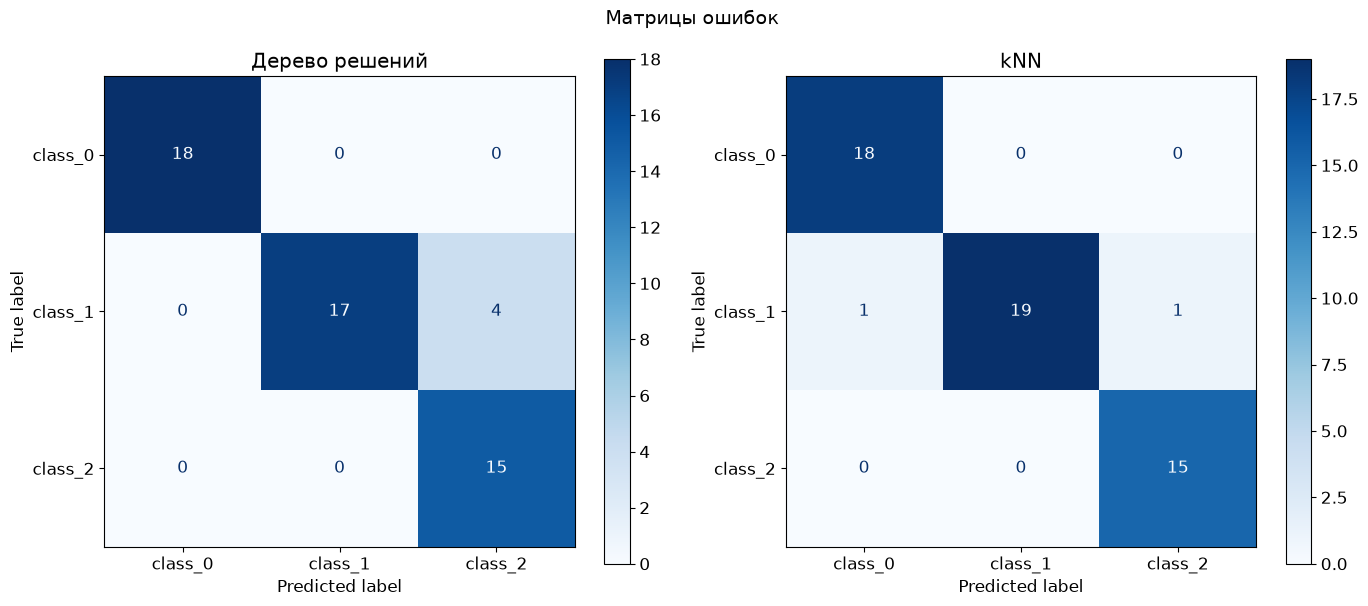

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tree,
                                       display_labels=wine.target_names,
                                       ax=axes[0], cmap='Blues')
axes[0].set_title('Дерево решений')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn,
                                       display_labels=wine.target_names,
                                       ax=axes[1], cmap='Blues')
axes[1].set_title('kNN')

plt.suptitle('Матрицы ошибок', fontsize=14)
plt.tight_layout()
plt.show()

Матрицы ошибок наглядно показывают, где каждый алгоритм ошибается. Дерево решений идеально классифицирует class_0, но часть образцов class_1 относит к class_2. kNN ошибается реже и распределяет ошибки равномернее между классами

## 6 ROC-кривые и ROC-AUC

Для трёх классов ROC строится как One-vs-Rest

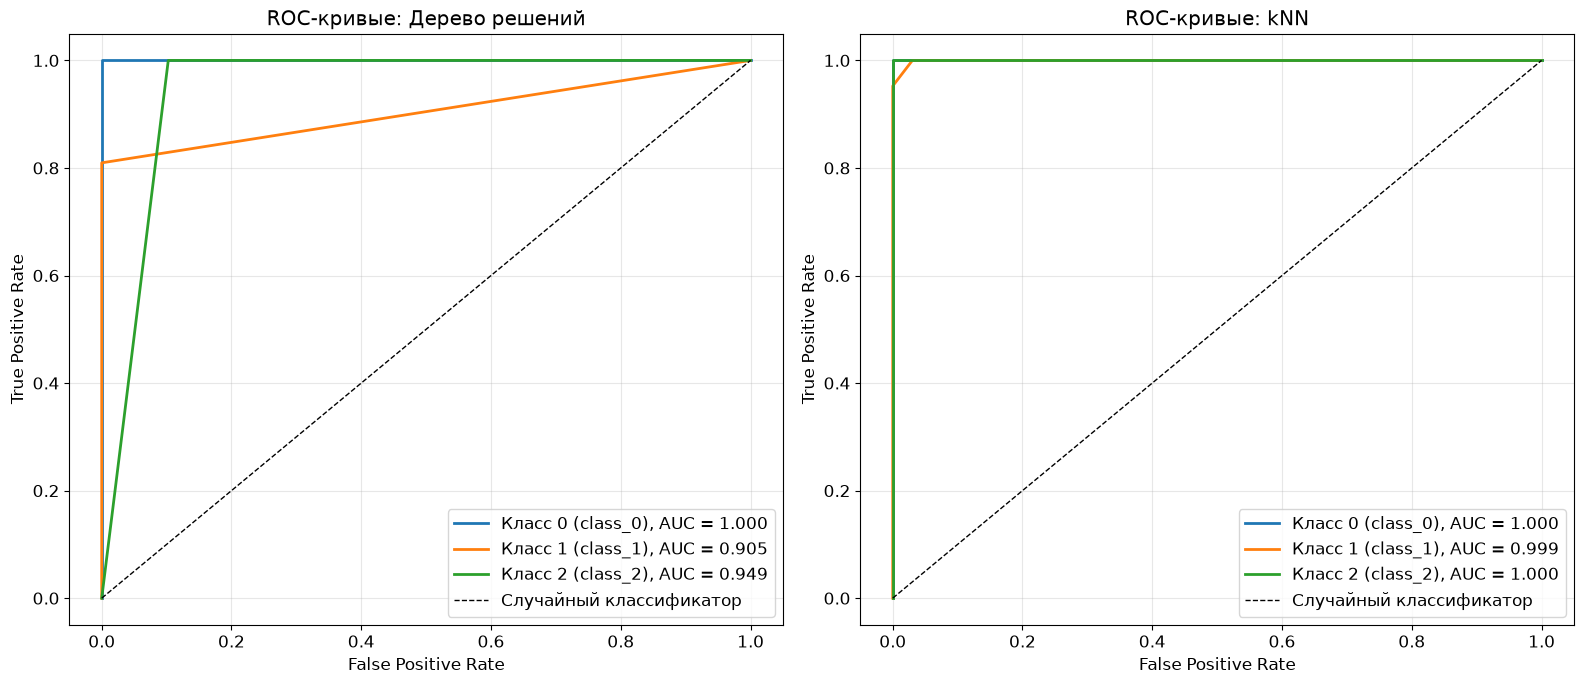

In [15]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = 3

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_tree[:, i])
    roc_auc_val = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, linewidth=2,
                 label=f'Класс {i} ({wine.target_names[i]}), AUC = {roc_auc_val:.3f}')

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Случайный классификатор')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC-кривые: Дерево решений')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_knn[:, i])
    roc_auc_val = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, linewidth=2,
                 label=f'Класс {i} ({wine.target_names[i]}), AUC = {roc_auc_val:.3f}')

axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Случайный классификатор')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые: kNN')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
roc_auc_tree = roc_auc_score(y_test, y_proba_tree, multi_class='ovr', average='macro')
roc_auc_knn = roc_auc_score(y_test, y_proba_knn, multi_class='ovr', average='macro')

print(f"ROC-AUC (macro, One-vs-Rest):")
print(f"  Дерево решений: {roc_auc_tree:.4f}")
print(f"  kNN:            {roc_auc_knn:.4f}")

ROC-AUC (macro, One-vs-Rest):
  Дерево решений: 0.9512
  kNN:            0.9998


## 7 Объяснение результатов

In [17]:
acc_tree = accuracy_score(y_test, y_pred_tree)
acc_knn = accuracy_score(y_test, y_pred_knn)
f1_tree = f1_score(y_test, y_pred_tree, average='macro')
f1_knn = f1_score(y_test, y_pred_knn, average='macro')

if acc_knn > acc_tree:
    better, worse = 'kNN', 'Дерево решений'
    better_acc, worse_acc = acc_knn, acc_tree
    better_f1, worse_f1 = f1_knn, f1_tree
    better_auc, worse_auc = roc_auc_knn, roc_auc_tree
else:
    better, worse = 'Дерево решений', 'kNN'
    better_acc, worse_acc = acc_tree, acc_knn
    better_f1, worse_f1 = f1_tree, f1_knn
    better_auc, worse_auc = roc_auc_tree, roc_auc_knn

print("Сравнительный анализ алгоритмов")
print("=" * 50)
print(f"\nЛучший алгоритм по Accuracy: {better} ({better_acc:.4f} vs {worse_acc:.4f})")
print(f"Лучший алгоритм по F1-macro: {'kNN' if f1_knn > f1_tree else 'Дерево решений'} ({max(f1_knn, f1_tree):.4f})")
print(f"Лучший алгоритм по ROC-AUC:  {'kNN' if roc_auc_knn > roc_auc_tree else 'Дерево решений'} ({max(roc_auc_knn, roc_auc_tree):.4f})")
print(f"\nРазница в Accuracy: {abs(acc_knn - acc_tree):.4f}")
print(f"Разница в ROC-AUC:  {abs(roc_auc_knn - roc_auc_tree):.4f}")

Сравнительный анализ алгоритмов

Лучший алгоритм по Accuracy: kNN (0.9630 vs 0.9259)
Лучший алгоритм по F1-macro: kNN (0.9636)
Лучший алгоритм по ROC-AUC:  kNN (0.9998)

Разница в Accuracy: 0.0370
Разница в ROC-AUC:  0.0486


Дерево решений хорошо работает на этом датасете благодаря чётким границам между классами, но склонно к переобучению - GridSearchCV помогает ограничить глубину

kNN эффективно использует то, что классы Wine хорошо разделимы в пространстве признаков (что было видно ещё в ЛР1). Масштабирование через StandardScaler выравнивает вклад признаков с разным диапазоном значений (от десятых долей до тысяч)

Высокие значения ROC-AUC у обоих алгоритмов означают, что модели уверенно разделяют классы, а не просто угадывают

## 8 Выводы

1. Датасет Wine подходит для классификации: целевой атрибут - сорт вина (3 класса), классы умеренно сбалансированы;

2. Данные разделены на обучающую и тестовую выборки с сохранением пропорций классов;

3. Гиперпараметры подобраны через GridSearchCV (cv=5): для дерева - max_depth и max_features, для kNN - n_neighbors;

4. Масштабирование (StandardScaler) применено для kNN через Pipeline, для дерева не требуется;

5. Оба алгоритма показали высокое качество классификации, что связано с хорошей разделимостью классов;

6. ROC-кривые обоих алгоритмов значительно выше диагонали случайного классификатора.